# Shao–Wu sem tanh: comparação de explosões

## Resumo
Este experimento compara a variante Shao–Wu anterior, que transforma cada lag com tanh, com uma variante sem essa transformação. Ambas usam o mesmo limite global de ganho, inovações gaussianas e histórico inicial uniforme sorteado diretamente. A variante nova rejeita propostas com derivadas globais não limitadas, como produtos entre dois lags. A comparação inclui também AST original, contração em domínio limitado e Heaps VAR, todos avaliados com 5.000 mecanismos, uma trajetória por mecanismo e os mesmos horizontes do notebook 6. Os resultados descrevem cruzamentos de um limite finito de amplitude, não uma prova empírica de estacionariedade.

A implementação do certificado está em src/tsfmxai/generators/shao_wu.py. O protocolo comum está em src/tsfmxai/evaluation/generator_tradeoff.py.

## 1. Configuração reproduzível

A semente, os horizontes, o limite de explosão e a gramática base coincidem com o notebook 6. A versão com tanh fica explicitamente configurada para conservar a referência anterior; a nova usa a transformação identidade.

In [1]:
from dataclasses import asdict, replace
from pathlib import Path
from time import perf_counter
import hashlib
import importlib.metadata
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "src" / "tsfmxai").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from tsfmxai.generators import (
    RandomTreeConfig, ContractionTreeConfig, ShaoWuConfig, HeapsVARConfig,
    sample_random_mechanisms, sample_contractive_mechanisms,
    sample_shao_wu_mechanisms, sample_shao_wu_trajectories,
    sample_heaps_var_mechanisms,
)
from tsfmxai.evaluation import StabilityDiagnosticConfig, wilson_interval
from tsfmxai.evaluation.generator_tradeoff import benchmark_stability_method
from tsfmxai.representations import Tanh, walk

BLAS_LIMIT = threadpool_limits(limits=1)
ROOT_SEED = 20261001
COUNT = 5000
HORIZONS = (96, 192, 384)
INNOVATION_STD = .05
DIAGNOSTICS = StabilityDiagnosticConfig(HORIZONS, 100., 3 * INNOVATION_STD, 24)
BASE = RandomTreeConfig(
    minimum_operators=1, maximum_operators=6, num_series=1,
    minimum_lag=1, maximum_lag=12, parameter_probability=.55,
    time_probability=0., lag_probability=.45, add_probability=.80,
    minimum_parameter_magnitude=.05, maximum_parameter_magnitude=.80,
    require_lag=True, require_time=False, coefficient_gate_lags=False,
)
BOUNDED = ContractionTreeConfig(
    tree_config=replace(BASE, coefficient_gate_lags=True),
    domain_radius=1., innovation_bound=np.sqrt(3.) * INNOVATION_STD,
    lag_weight_growth=1.25, target_lipschitz=.90, scale_safety_factor=.95,
)
SHAO_OLD = ShaoWuConfig(tree_config=BASE, innovation_std=INNOVATION_STD,
                         target_gain=.8, lag_transform="tanh")
SHAO_NEW = replace(SHAO_OLD, lag_transform="identity")
HEAPS = HeapsVARConfig(num_series=1, minimum_order=1, maximum_order=12,
                       unconstrained_std=.45, innovation_std=INNOVATION_STD)
METHODS = ("original", "bounded-domain", "shao-wu-tanh", "shao-wu-no-tanh", "heaps-var")
print(json.dumps({
    "root_seed": ROOT_SEED, "count_per_method": COUNT,
    "horizons": HORIZONS, "diagnostics": asdict(DIAGNOSTICS),
    "old_lag_transform": SHAO_OLD.lag_transform,
    "new_lag_transform": SHAO_NEW.lag_transform,
    "blas_threads": 1,
}, indent=2))

{
  "root_seed": 20261001,
  "count_per_method": 5000,
  "horizons": [
    96,
    192,
    384
  ],
  "diagnostics": {
    "horizons": [
      96,
      192,
      384
    ],
    "explosion_limit": 100.0,
    "near_zero_radius": 0.15000000000000002,
    "near_zero_tail_steps": 24
  },
  "old_lag_transform": "tanh",
  "new_lag_transform": "identity",
  "blas_threads": 1
}


**O que foi feito.** Esta célula fixa todas as escolhas que afetam a amostragem e a classificação, evitando que uma diferença de parâmetros seja confundida com o efeito de remover tanh.

## 2. Amostrar mecanismos

O novo sorteador conserva propostas cuja derivada global é limitada. Uma proposta rejeitada é reamostrada com uma semente derivada do mesmo índice; registramos quantas tentativas foram necessárias. Isso altera a distribuição das árvores aceitas, portanto a comparação não é pareada árvore a árvore.

In [2]:
samplers = {
    "original": lambda: sample_random_mechanisms(BASE, root_seed=ROOT_SEED, count=COUNT),
    "bounded-domain": lambda: sample_contractive_mechanisms(BOUNDED, root_seed=ROOT_SEED, count=COUNT),
    "shao-wu-tanh": lambda: sample_shao_wu_mechanisms(SHAO_OLD, root_seed=ROOT_SEED, count=COUNT),
    "shao-wu-no-tanh": lambda: sample_shao_wu_mechanisms(SHAO_NEW, root_seed=ROOT_SEED, count=COUNT),
    "heaps-var": lambda: sample_heaps_var_mechanisms(HEAPS, root_seed=ROOT_SEED, count=COUNT),
}
mechanisms = {}
sampling_seconds = {}
for method in METHODS:
    started = perf_counter()
    mechanisms[method] = samplers[method]()
    sampling_seconds[method] = perf_counter() - started
    assert len(mechanisms[method]) == COUNT
    if method != "original":
        assert all(m.certificate.holds for m in mechanisms[method])
    print(method, "sampling seconds:", round(sampling_seconds[method], 2), flush=True)

new_mechanisms = mechanisms["shao-wu-no-tanh"]
assert all(not isinstance(node, Tanh) for m in new_mechanisms
           for e in m.expressions for node in walk(e))
proposal_attempts = np.array([m.proposal_attempt for m in new_mechanisms])
proposal_summary = {
    "accepted_mechanisms": COUNT,
    "rejected_proposals": int(proposal_attempts.sum()),
    "total_proposals": int(COUNT + proposal_attempts.sum()),
    "acceptance_fraction": float(COUNT / (COUNT + proposal_attempts.sum())),
    "maximum_rejections_for_one_mechanism": int(proposal_attempts.max()),
}
display(pd.DataFrame([
    {"method": method,
     "formula": mechanisms[method][0].formulas[0]
                if hasattr(mechanisms[method][0], "formulas")
                else mechanisms[method][0].formula}
    for method in METHODS
]))
print(proposal_summary)

original sampling seconds: 1.86


bounded-domain sampling seconds: 3.97


shao-wu-tanh sampling seconds: 6.91


shao-wu-no-tanh sampling seconds: 5.66


heaps-var sampling seconds: 20.64


,method,formula
0,original,(x_0(t-7) + ((-0.727339 + 0.163988) + -0.752925))
1,bounded-domain,x_0(t) = (0.611596 * ((0.102517 * x_0(t-7)) + ...
2,shao-wu-tanh,x_0(t) = (0.76 * (tanh(x_0(t-7)) + ((-0.727339...
3,shao-wu-no-tanh,x_0(t) = (0.76 * (x_0(t-7) + ((-0.727339 + 0.1...
4,heaps-var,x_0(t) = ((((((0 + (-0.00640847 * x_0(t-1))) +...


{'accepted_mechanisms': 5000, 'rejected_proposals': 1257, 'total_proposals': 6257, 'acceptance_fraction': 0.799105002397315, 'maximum_rejections_for_one_mechanism': 4}


**O que foi feito.** Amostramos 5.000 mecanismos por método, verificamos os certificados e confirmamos que nenhuma árvore aceita pela variante nova contém tanh. O número de rejeições mostra o custo de restringir a gramática ao subconjunto globalmente Lipschitz.

## 3. Gerar e classificar uma trajetória por mecanismo

O avaliador usa apenas os passos produzidos pela recorrência; o histórico inicial é registrado separadamente. Uma explosão significa valor não finito ou cruzamento do limite absoluto 100 até o horizonte indicado. Todos os mecanismos tentados entram no denominador, inclusive os que falham antes do último passo.

In [3]:
results = {}
for method in METHODS:
    result = benchmark_stability_method(
        method, mechanisms[method], root_seed=ROOT_SEED,
        diagnostic_config=DIAGNOSTICS, innovation_std=INNOVATION_STD,
        sampling_seconds=sampling_seconds[method], keep_examples=2,
    )
    results[method] = result
    print(method, "evaluation seconds:",
          round(result["performance"]["evaluation_seconds"], 2), flush=True)

outcomes = pd.DataFrame(row for method in METHODS for row in results[method]["outcomes"])
summary = outcomes.groupby(["method", "horizon"], sort=False).agg(
    attempts=("sample_index", "size"),
    explosions=("exploded", "sum"),
    near_zero=("near_zero", "sum"),
    nonfinite=("nonfinite", "sum"),
).reset_index()
summary["explosion_pct"] = 100 * summary["explosions"] / summary["attempts"]
summary["near_zero_pct"] = 100 * summary["near_zero"] / summary["attempts"]
summary["explosion_wilson_95"] = [
    tuple(round(100 * v, 3) for v in wilson_interval(int(k), int(n)))
    for k, n in zip(summary.explosions, summary.attempts)
]
display(summary)
assert summary.attempts.eq(COUNT).all()
baseline = summary[summary.horizon.eq(384)].set_index("method")
assert (baseline.loc[["bounded-domain", "shao-wu-tanh", "heaps-var"], "explosions"] == 0).all()
print("Observed explosion counts at horizon 384:")
print(baseline["explosions"].to_string())

original evaluation seconds: 23.94


bounded-domain evaluation seconds: 49.86


shao-wu-tanh evaluation seconds: 54.55


shao-wu-no-tanh evaluation seconds: 50.3


heaps-var evaluation seconds: 62.38


,method,horizon,attempts,explosions,near_zero,nonfinite,explosion_pct,near_zero_pct,explosion_wilson_95
0,original,96,5000,2298,519,0,45.96,10.38,"(44.582, 47.344)"
1,original,192,5000,2466,528,0,49.32,10.56,"(47.935, 50.706)"
2,original,384,5000,2643,540,0,52.86,10.80,"(51.475, 54.241)"
3,bounded-domain,96,5000,0,2210,0,0.00,44.20,"(0.0, 0.077)"
4,bounded-domain,192,5000,0,2210,0,0.00,44.20,"(0.0, 0.077)"
5,bounded-domain,384,5000,0,2209,0,0.00,44.18,"(0.0, 0.077)"
6,shao-wu-tanh,96,5000,0,1180,0,0.00,23.60,"(0.0, 0.077)"
7,shao-wu-tanh,192,5000,0,1189,0,0.00,23.78,"(0.0, 0.077)"
8,shao-wu-tanh,384,5000,0,1174,0,0.00,23.48,"(0.0, 0.077)"
9,shao-wu-no-tanh,96,5000,0,701,0,0.00,14.02,"(0.0, 0.077)"


Observed explosion counts at horizon 384:
method
original           2643
bounded-domain        0
shao-wu-tanh          0
shao-wu-no-tanh       0
heaps-var             0


**O que foi feito.** Cada mecanismo gerou uma trajetória com ruído independente. A tabela compara explosão e baixa amplitude nos três horizontes, com intervalo de Wilson para a taxa de explosão. Os resultados dos quatro métodos anteriores são conferidos contra o notebook 6.

## 4. Visualizar as trajetórias Shao–Wu

A linha vertical marca o primeiro passo gerado; os valores anteriores são apenas o histórico inicial exigido pelos lags. Cada linha mostra uma variante e cada coluna uma trajetória independente do primeiro mecanismo amostrado.

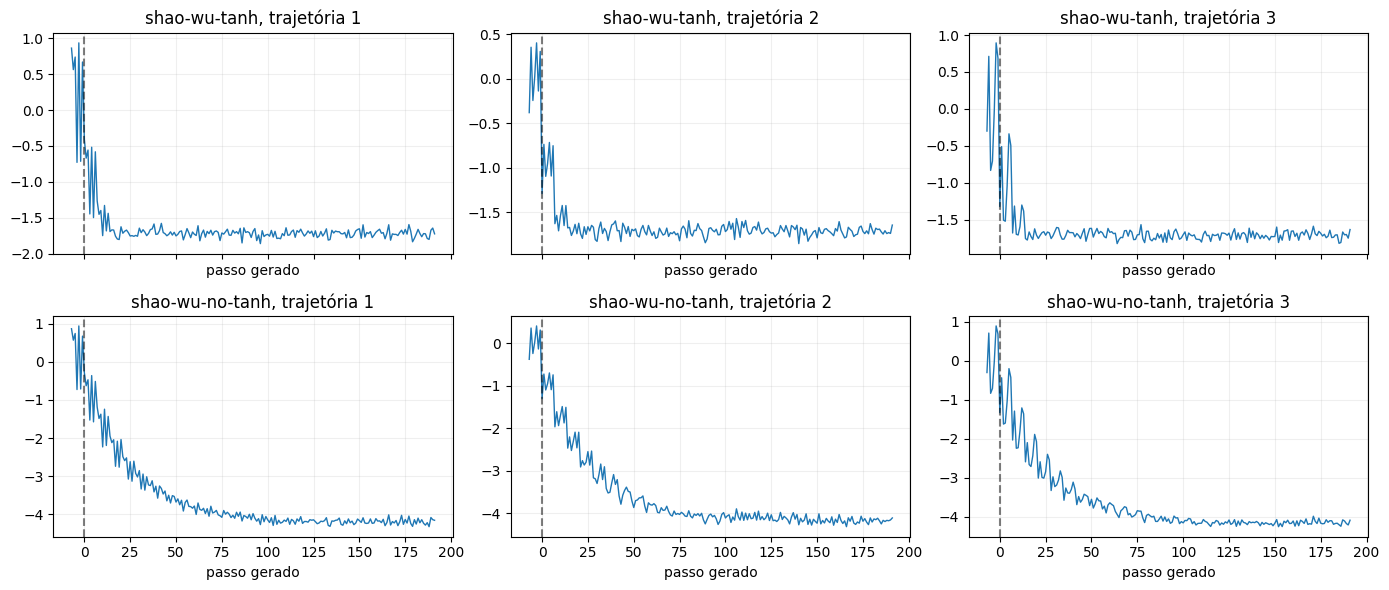

Fórmula antiga: x_0(t) = (0.76 * (tanh(x_0(t-7)) + ((-0.727339 + 0.163988) + -0.752925))) + epsilon_0(t)
Fórmula nova: x_0(t) = (0.76 * (x_0(t-7) + ((-0.727339 + 0.163988) + -0.752925))) + epsilon_0(t)


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for row, method in enumerate(("shao-wu-tanh", "shao-wu-no-tanh")):
    mechanism = mechanisms[method][0]
    paths = sample_shao_wu_trajectories(
        mechanism, trajectory_count=3, generated_steps=192, root_seed=812)
    for col in range(3):
        ax = axes[row, col]
        ax.plot(np.arange(-mechanism.order, 192), paths[col, 0], lw=1)
        ax.axvline(0, color="black", ls="--", alpha=.5)
        ax.set(title=f"{method}, trajetória {col+1}", xlabel="passo gerado")
        ax.grid(alpha=.2)
fig.tight_layout()
plt.show()
print("Fórmula antiga:", mechanisms["shao-wu-tanh"][0].formulas[0])
print("Fórmula nova:", mechanisms["shao-wu-no-tanh"][0].formulas[0])

**O que foi feito.** O gráfico permite comparar a aparência das realizações. Uma única fórmula e poucas trajetórias ilustram o mecanismo; as taxas da seção anterior vêm das 5.000 amostras por método.

## 5. Registro completo do experimento

Este bloco reúne configuração, proveniência, sementes, métricas, interpretação, limites e comando de reprodução. Os resultados anteriores do notebook 6 permanecem arquivados, sem alterar o relatório.

In [5]:
source_files = (
    "src/tsfmxai/generators/shao_wu.py",
    "src/tsfmxai/generators/random_expression.py",
    "src/tsfmxai/generators/contraction.py",
    "src/tsfmxai/generators/heaps.py",
    "src/tsfmxai/evaluation/generator_tradeoff.py",
    "src/tsfmxai/evaluation/stability.py",
)
source_hashes = {
    name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest()
    for name in source_files
}
record = {
    "experiment_id": "shao_wu_no_tanh_comparison_001",
    "research_question": "Como retirar tanh do gerador Shao-Wu altera as taxas de explosão frente à variante anterior e aos outros três métodos?",
    "hypothesis": "O ganho global abaixo de um reduz cruzamentos do limite operacional, mas a nova restrição elimina produtos entre lags e altera a distribuição das fórmulas.",
    "configuration": {
        "root_seed": ROOT_SEED, "mechanisms_per_method": COUNT,
        "trajectories_per_mechanism": 1, "num_series": 1,
        "horizons": HORIZONS, "diagnostics": asdict(DIAGNOSTICS),
        "innovation_std": INNOVATION_STD, "base_tree": asdict(BASE),
        "bounded_domain": asdict(BOUNDED), "shao_wu_old": asdict(SHAO_OLD),
        "shao_wu_new": asdict(SHAO_NEW), "heaps": asdict(HEAPS),
        "blas_threads": 1,
    },
    "provenance": {
        "python": platform.python_version(), "platform": platform.platform(),
        "numpy": np.__version__, "pandas": pd.__version__,
        "matplotlib": importlib.metadata.version("matplotlib"),
        "source_sha256": source_hashes,
    },
    "seed_usage": {
        "mechanisms": "derive_sample_seed(ROOT_SEED, sample_index)",
        "shao_wu_identity_retries": "attempt 0 uses the original seed; attempts >0 use derive_sample_seed(seed, attempt)",
        "initialization_and_noise": "SeedSequence([ROOT_SEED, sample_index, 991]).spawn(2)",
        "visualization": "separate trajectory root seed 812",
    },
    "metrics": {
        "rates_by_method_and_horizon": summary.to_dict(orient="records"),
        "proposal_sampling": proposal_summary,
        "performance": [results[m]["performance"] for m in METHODS],
    },
    "scientific_summary": (
        f"At h=384, explosions were "
        + ", ".join(f"{m}: {int(baseline.loc[m, 'explosions'])}/{COUNT}"
                    for m in METHODS)
        + ". The unsaturated family contains no tanh nodes and accepts "
        + f"{proposal_summary['acceptance_fraction']:.1%} of proposed trees."
    ),
    "limitations": [
        "The new sampler conditions on finite global derivative bounds, so nonlinear lag-by-lag products are absent.",
        "Identical root seeds do not imply paired formulas after the unsaturated sampler rejects a proposal.",
        "An observed zero rate at finite h and threshold 100 is not proof of pathwise boundedness or exact stationary initialization.",
        "Noise support differs: the bounded-domain method uses uniform innovations; other methods use Gaussian innovations.",
        "Runtime is one serial realization per method, not a timing confidence interval.",
    ],
    "reproduction_command": r".\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace experiments/abstract_syntax_tree/shao_wu_no_tanh_comparison/00_explosion_comparison.ipynb",
}
print(json.dumps(record, indent=2, default=str))

{
  "experiment_id": "shao_wu_no_tanh_comparison_001",
  "research_question": "Como retirar tanh do gerador Shao-Wu altera as taxas de explos\u00e3o frente \u00e0 variante anterior e aos outros tr\u00eas m\u00e9todos?",
  "hypothesis": "O ganho global abaixo de um reduz cruzamentos do limite operacional, mas a nova restri\u00e7\u00e3o elimina produtos entre lags e altera a distribui\u00e7\u00e3o das f\u00f3rmulas.",
  "configuration": {
    "root_seed": 20261001,
    "mechanisms_per_method": 5000,
    "trajectories_per_mechanism": 1,
    "num_series": 1,
    "horizons": [
      96,
      192,
      384
    ],
    "diagnostics": {
      "horizons": [
        96,
        192,
        384
      ],
      "explosion_limit": 100.0,
      "near_zero_radius": 0.15000000000000002,
      "near_zero_tail_steps": 24
    },
    "innovation_std": 0.05,
    "base_tree": {
      "minimum_operators": 1,
      "maximum_operators": 6,
      "num_series": 1,
      "minimum_lag": 1,
      "maximum_lag": 12

**O que foi feito.** O registro salva, no próprio notebook executado, todos os dados necessários para interpretar e repetir a comparação sem arquivos auxiliares.